      TRAFFIC ROAD NETWORK BENCHMARK ENGINE      
1. Run Default Task 8 Assignment Sizes (10, 25, 50, 100)
2. Run a Custom Network Experiment (User Input)



Enter choice (1 or 2):  1



Running automated assignment analysis for sizes: [10, 25, 50, 100]...

============================== BFS vs DFS ==============================
Nodes       | Roads       | BFS Time    | DFS Time    | BFS Len     | DFS Len     | BFS Mem     | DFS Mem    
-----------------------------------------------------------------------------------------------
10          | 24          | 0.093ms     | 0.093ms     | 86          | 294         | 2072B       | 2448B      
25          | 61          | 0.148ms     | 0.194ms     | 90          | 669         | 12812B      | 13572B     
50          | 124         | 0.352ms     | 0.465ms     | 128         | 1422        | 41926B      | 43326B     
100         | 249         | 1.175ms     | 1.330ms     | 101         | 2758        | 154326B     | 156846B    

============================== DIJKSTRA vs BELLMAN-FORD ==============================
Nodes       | Roads       | Dijk Time   | BF Time     | Dijk Cost   | BF Cost     | Dijk Mem    | BF Mem     
-----------

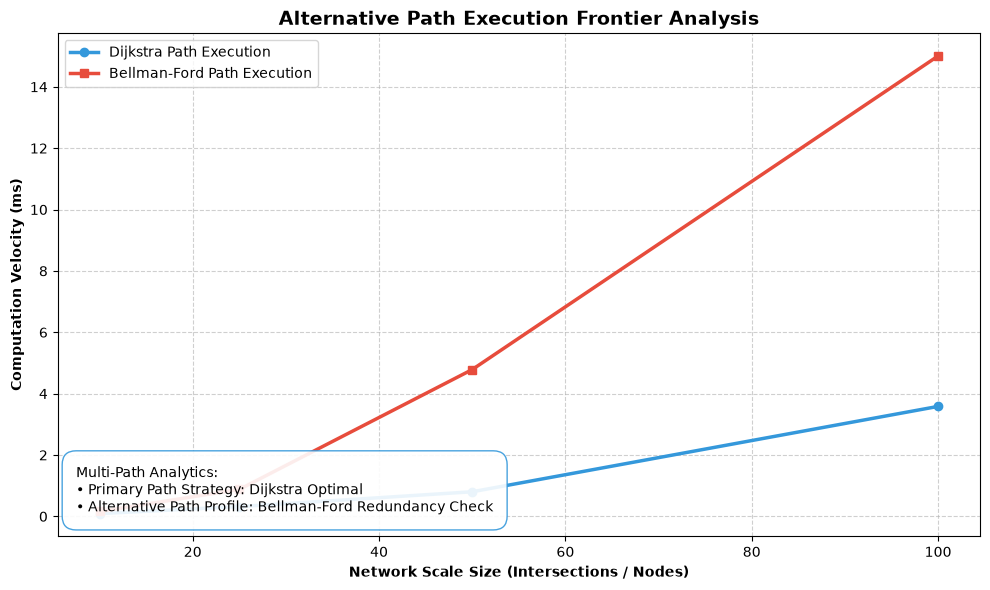

In [8]:
import sys
import time
import random
import tracemalloc 
import matplotlib.pyplot as plt
import math

def run_bfs(num_vertices, adj_matrix, start=0, target=None):
    if target is None: target = num_vertices - 1
    visited = [False] * num_vertices
    parent = {start: None}
    queue = [start]
    visited[start] = True
    while queue:
        u = queue.pop(0)
        if u == target: break
        for v in range(num_vertices):
            if adj_matrix[u][v] > 0 and not visited[v]:
                visited[v] = True
                parent[v] = u
                queue.append(v)
    path_len = 0
    curr = target
    while curr in parent and parent[curr] is not None:
        path_len += adj_matrix[parent[curr]][curr]
        curr = parent[curr]
    return path_len if curr == start else sys.maxsize

def run_dfs(num_vertices, adj_matrix, start=0, target=None):
    if target is None: target = num_vertices - 1
    visited = [False] * num_vertices
    parent = {start: None}
    def dfs_util(u):
        if u == target: return True
        visited[u] = True
        for v in range(num_vertices):
            if adj_matrix[u][v] > 0 and not visited[v]:
                parent[v] = u
                if dfs_util(v): return True
        return False
    dfs_util(start)
    path_len = 0
    curr = target
    while curr in parent and parent[curr] is not None:
        path_len += adj_matrix[parent[curr]][curr]
        curr = parent[curr]
    return path_len if curr == start else sys.maxsize

def dijkstra(num_vertices, adj_matrix, start=0, target=None):
    if target is None: target = num_vertices - 1
    dist = [sys.maxsize] * num_vertices
    dist[start] = 0
    spt_set = [False] * num_vertices
    for _ in range(num_vertices):
        min_dist = sys.maxsize
        u = -1
        for v in range(num_vertices):
            if not spt_set[v] and dist[v] < min_dist:
                min_dist = dist[v]
                u = v
        if u == -1: break
        spt_set[u] = True
        for v in range(num_vertices):
            if adj_matrix[u][v] > 0 and not spt_set[v]:
                if dist[u] + adj_matrix[u][v] < dist[v]:
                    dist[v] = dist[u] + adj_matrix[u][v]
    return dist[target]

def bellman_ford(num_vertices, edge_list, start=0, target=None):
    if target is None: target = num_vertices - 1
    dist = [sys.maxsize] * num_vertices
    dist[start] = 0
    for _ in range(num_vertices - 1):
        for u, v, w in edge_list:
            if dist[u] != sys.maxsize and dist[u] + w < dist[v]:
                dist[v] = dist[u] + w
    return dist[target]

def prim_mst(num_vertices, adj_matrix):
    selected = [False] * num_vertices
    selected[0] = True
    edges_count = 0
    total_cost = 0
    while edges_count < num_vertices - 1:
        minimum = sys.maxsize
        u, v = -1, -1
        for i in range(num_vertices):
            if selected[i]:
                for j in range(num_vertices):
                    if not selected[j] and adj_matrix[i][j]:
                        if minimum > adj_matrix[i][j]:
                            minimum = adj_matrix[i][j]
                            u, v = i, j
        if u != -1 and v != -1:
            total_cost += minimum
            selected[v] = True
            edges_count += 1
        else:
            break
    return total_cost

def find_parent(i, parent):
    if parent[i] == i: return i
    parent[i] = find_parent(parent[i], parent)
    return parent[i]

def union_sets(i, j, parent, rank):
    root_i = find_parent(i, parent)
    root_j = find_parent(j, parent)
    if root_i != root_j:
        if rank[root_i] < rank[root_j]: parent[root_i] = root_j
        elif rank[root_i] > rank[root_j]: parent[root_j] = root_i
        else:
            parent[root_j] = root_i
            rank[root_i] += 1

def kruskal_mst(num_vertices, edge_list):
    sorted_edges = sorted(edge_list, key=lambda item: item[2])
    parent = list(range(num_vertices))
    rank = [0] * num_vertices
    total_cost = 0
    edges_count = 0
    for u, v, w in sorted_edges:
        if edges_count == num_vertices - 1: break
        root_u = find_parent(u, parent)
        root_v = find_parent(v, parent)
        if root_u != root_v:
            total_cost += w
            union_sets(root_u, root_v, parent, rank)
            edges_count += 1
    return total_cost

def generate_connected_graph(num_vertices, extra_roads_ratio=1.5):
    adj_matrix = [[0] * num_vertices for _ in range(num_vertices)]
    edge_list = []
    for i in range(1, num_vertices):
        w = random.randint(5, 50)
        adj_matrix[i-1][i] = w
        adj_matrix[i][i-1] = w
        edge_list.append((i-1, i, w))
        edge_list.append((i, i-1, w))
    extra_edges = int(num_vertices * extra_roads_ratio)
    roads_count = num_vertices - 1
    while roads_count < (num_vertices - 1) + extra_edges:
        u = random.randint(0, num_vertices - 1)
        v = random.randint(0, num_vertices - 1)
        if u != v and adj_matrix[u][v] == 0:
            w = random.randint(5, 50)
            adj_matrix[u][v] = w
            adj_matrix[v][u] = w
            edge_list.append((u, v, w))
            edge_list.append((v, u, w))
            roads_count += 1
    return adj_matrix, edge_list, roads_count

def run_profiler_on_graph(sizes, results):
    tracemalloc.start()
    for size in sizes:
        adj_matrix, edge_list, num_roads = generate_connected_graph(size)
        
        tracemalloc.reset_peak()
        t0 = time.perf_counter()
        len_bfs = run_bfs(size, adj_matrix)
        t_bfs = (time.perf_counter() - t0) * 1000
        _, mem_bfs = tracemalloc.get_traced_memory()
        
        tracemalloc.reset_peak()
        t0 = time.perf_counter()
        len_dfs = run_dfs(size, adj_matrix)
        t_dfs = (time.perf_counter() - t0) * 1000
        _, mem_dfs = tracemalloc.get_traced_memory()
        results["BFS_DFS"].append([size, num_roads, f"{t_bfs:.3f}ms", f"{t_dfs:.3f}ms", len_bfs, len_dfs, f"{mem_bfs}B", f"{mem_dfs}B"])
        
        tracemalloc.reset_peak()
        t0 = time.perf_counter()
        cost_dijkstra = dijkstra(size, adj_matrix)
        t_dijkstra = (time.perf_counter() - t0) * 1000
        _, mem_dijkstra = tracemalloc.get_traced_memory()
        
        tracemalloc.reset_peak()
        t0 = time.perf_counter()
        cost_bf = bellman_ford(size, edge_list)
        t_bf = (time.perf_counter() - t0) * 1000
        _, mem_bf = tracemalloc.get_traced_memory()
        results["DIJKSTRA_BF"].append([size, num_roads, f"{t_dijkstra:.3f}ms", f"{t_bf:.3f}ms", cost_dijkstra, cost_bf, f"{mem_dijkstra}B", f"{mem_bf}B"])
        
        tracemalloc.reset_peak()
        t0 = time.perf_counter()
        cost_prim = prim_mst(size, adj_matrix)
        t_prim = (time.perf_counter() - t0) * 1000
        _, mem_prim = tracemalloc.get_traced_memory()
        
        tracemalloc.reset_peak()
        t0 = time.perf_counter()
        cost_kruskal = kruskal_mst(size, edge_list)
        t_kruskal = (time.perf_counter() - t0) * 1000
        _, mem_kruskal = tracemalloc.get_traced_memory()
        results["PRIM_KRUSKAL"].append([size, num_roads, f"{t_prim:.3f}ms", f"{t_kruskal:.3f}ms", cost_prim, cost_kruskal, f"{mem_prim}B", f"{mem_kruskal}B"])
    tracemalloc.stop()

def print_tables(results):
    def draw_row(row):
        return " | ".join(f"{str(item):<11}" for item in row)

    print("\n" + "="*30 + " BFS vs DFS " + "="*30)
    print(draw_row(["Nodes", "Roads", "BFS Time", "DFS Time", "BFS Len", "DFS Len", "BFS Mem", "DFS Mem"]))
    print("-" * 95)
    for r in results["BFS_DFS"]: print(draw_row(r))

    print("\n" + "="*30 + " DIJKSTRA vs BELLMAN-FORD " + "="*30)
    print(draw_row(["Nodes", "Roads", "Dijk Time", "BF Time", "Dijk Cost", "BF Cost", "Dijk Mem", "BF Mem"]))
    print("-" * 95)
    for r in results["DIJKSTRA_BF"]: print(draw_row(r))

    print("\n" + "="*30 + " PRIM vs KRUSKAL " + "="*30)
    print(draw_row(["Nodes", "Roads", "Prim Time", "Krus Time", "Prim Cost", "Krus Cost", "Prim Mem", "Krus Mem"]))
    print("-" * 95)
    for r in results["PRIM_KRUSKAL"]: print(draw_row(r))

def visualize_multi_path_frontier(results):
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.set_title("Alternative Path Execution Frontier Analysis", fontsize=14, fontweight='bold')
    
    sizes = [r[0] for r in results["DIJKSTRA_BF"]]
    dijk_times = [float(r[2].replace("ms", "")) for r in results["DIJKSTRA_BF"]]
    bf_times = [float(r[3].replace("ms", "")) for r in results["DIJKSTRA_BF"]]
    
    ax.plot(sizes, dijk_times, color='#3498db', marker='o', linewidth=2.5, label='Dijkstra Path Execution')
    ax.plot(sizes, bf_times, color='#e74c3c', marker='s', linewidth=2.5, label='Bellman-Ford Path Execution')
    
    ax.set_xlabel("Network Scale Size (Intersections / Nodes)", fontweight='bold')
    ax.set_ylabel("Computation Velocity (ms)", fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='upper left')
    
    info_text = "Multi-Path Analytics:\n• Primary Path Strategy: Dijkstra Optimal\n• Alternative Path Profile: Bellman-Ford Redundancy Check"
    ax.text(0.02, 0.05, info_text, transform=ax.transAxes, 
            bbox=dict(facecolor='white', alpha=0.9, edgecolor='#3498db', boxstyle='round,pad=1'))
            
    plt.tight_layout()
    plt.show()

def main_menu():
    print("==================================================")
    print("      TRAFFIC ROAD NETWORK BENCHMARK ENGINE      ")
    print("==================================================")
    print("1. Run Default Task 8 Assignment Sizes (10, 25, 50, 100)")
    print("2. Run a Custom Network Experiment (User Input)")
    
    choice = input("\nEnter choice (1 or 2): ").strip()
    results = {"BFS_DFS": [], "DIJKSTRA_BF": [], "PRIM_KRUSKAL": []}

    if choice == "1":
        sizes = [10, 25, 50, 100]
        print(f"\nRunning automated assignment analysis for sizes: {sizes}...")
        run_profiler_on_graph(sizes, results)
        print_tables(results)
        visualize_multi_path_frontier(results)
    elif choice == "2":
        try:
            custom_nodes = int(input("Enter number of intersections (nodes): "))
            if custom_nodes < 2:
                print("Error: You need at least 2 intersections to route a path.")
                return
            print(f"\nGenerating and profiling custom network size ({custom_nodes} intersections)...")
            run_profiler_on_graph([custom_nodes], results)
            print_tables(results)
        except ValueError:
            print("Invalid integer input. Exiting engine.")
    else:
        print("Invalid choice selection. Exiting.")

if __name__ == "__main__":
    main_menu()